In [1]:
from astropy import units as u
from astropy import constants as const
from synphot import units, SourceSpectrum
from synphot.models import BlackBodyNorm1D, GaussianFlux1D
import matplotlib.pyplot as plt

from synphot import SpectralElement
from synphot.models import Box1D
import matplotlib.gridspec as gridspec

from astroquery.svo_fps import SvoFps
import numpy as np

from synphot.models import Empirical1D
filters = SvoFps.get_filter_list('JWST', instrument='NIRCam')
print(filters['filterID'])


       filterID      
                     
---------------------
    JWST/NIRCam.F070W
JWST/NIRCam2025.F070W
    JWST/NIRCam.F090W
JWST/NIRCam2025.F090W
JWST/NIRCam2025.F115W
    JWST/NIRCam.F115W
    JWST/NIRCam.F140M
JWST/NIRCam2025.F140M
    JWST/NIRCam.F150W
                  ...
JWST/NIRCam2025.F444W
    JWST/NIRCam.F444W
JWST/NIRCam2025.F460M
    JWST/NIRCam.F460M
JWST/NIRCam2025.F466N
    JWST/NIRCam.F466N
    JWST/NIRCam.F470N
JWST/NIRCam2025.F470N
JWST/NIRCam2025.F480M
    JWST/NIRCam.F480M
Length = 58 rows


0.00129535578262078 PHOTLAM
8.57718042640319e-15 FLAM
SourceSpectrum at z=0.0
Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: ([0] | [1]) + [2] - [3]
Components: 
    [0]: <BlackBodyNorm1D(temperature=6000.)>

    [1]: <Scale(factor=2.)>

    [2]: <GaussianFlux1D(amplitude=0.00049657, mean=3000., stddev=42.46609001)>

    [3]: <GaussianFlux1D(amplitude=0.0003773, mean=4000., stddev=20.)>
Parameters:
    temperature_0 factor_1      amplitude_2      ... mean_3 stddev_3
    ------------- -------- --------------------- ... ------ --------
           6000.0      2.0 0.0004965698607312611 ... 4000.0     20.0


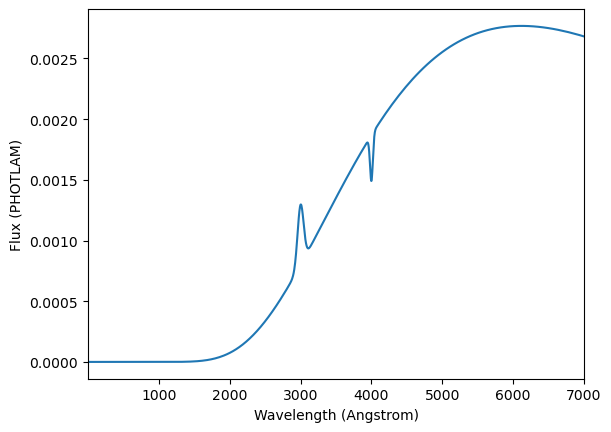

In [2]:
g_abs = SourceSpectrum(GaussianFlux1D, amplitude=1*u.mJy,
                       mean=4000, stddev=20)

g_em = SourceSpectrum(GaussianFlux1D,
                      total_flux=3.5e-13*u.erg/(u.cm**2 * u.s),
                      mean=3000, fwhm=100)
bb = SourceSpectrum(BlackBodyNorm1D, temperature=6000)


sp = 2 * bb + g_em - g_abs
sp.plot(left=1, right=7000)
print(sp(0.3 * u.micron))
print(sp(0.3 * u.micron, flux_unit=units.FLAM))
sp(sp.waveset)
print(sp)



In [3]:
bp = SpectralElement(Box1D, amplitude=1, x_0=4000, width=2000)

sp_rn = sp.normalize(1 * u.Jy, band=bp)
sp_rn.integrate()

<Quantity 6884.50783602 ph / (s cm2)>

In [4]:

obs = Observation(sp_rn, bp)
import numpy as np
area = np.pi * (1 * u.m) ** 2
obs.countrate(area=area)

NameError: name 'Observation' is not defined

In [ ]:

dirname= 'bessell_for_luka/'
file   = 'cm05_03500.asc' 

data = np.loadtxt(dirname + file)



In [ ]:
fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(1, 1, figure=fig, wspace=0.0, hspace=0.0)
ax0 = fig.add_subplot(gs[0, 0])

wave, flux = data.T
ax0.plot(wave, flux)

ax0.set_title('Stellar Continuum log[M/H] = -0.5]')
ax0.set_xlabel('')
ax0.set_ylabel('SED')
ax0.set_xlim(3000, 50000)
ax0.set_xlim(18000, 20000)

plt.show()

In [ ]:
paths, temps = Find_available_models()

C1 = []
C2 = []
for T_eff in temps:
    C1.append((Compute_model_MAG(T_eff = T_eff, filter = 'F115W') - Compute_model_MAG(T_eff = T_eff, filter = 'F200W')).value)
    C2.append((Compute_model_MAG(T_eff = T_eff, filter = 'F115W') - Compute_model_MAG(T_eff = T_eff, filter = 'F187N')).value )
    
C1 = np.array(C1)
C2 = np.array(C2)
def _make_mag_name(filter):
    return fr'$m_{{\mathrm{{{str(filter)}}}}}$'


/var/tmp/slagter/ipykernel_772661/1532834144.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


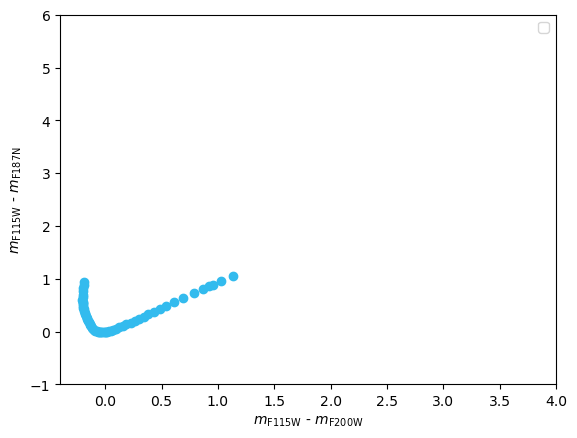

In [ ]:
fig = plt.figure()
gs = gridspec.GridSpec(1,1, figure=fig)
ax  = fig.add_subplot(gs[0,0])


ax.set_xlabel(f'{_make_mag_name('F115W')} - {_make_mag_name('F200W')}')
ax.set_ylabel(f'{_make_mag_name('F115W')} - {_make_mag_name('F187N')}')

ax.scatter(C1, C2,  color = '#33BBEE')

ax.set_xlim( (-0.4,4))
ax.set_ylim((-1,6))

ax.legend()



In [108]:
from astropy.table import Table

dirname= 'bessell_for_luka/'
file   = 'cm05_03500.fits' 
t = Table.read(dirname + file, format='fits')
print(t.colnames)


cm05_03500_spec = SourceSpectrum.from_file('ckm05_4750.fits', wave_col='WAVELENGTH', wave_unit='ANGSTROMS', flux_col='g50', flux_unit='FLAM')
sp = cm05_03500_spec


['WAVELENGTH', 'g00', 'g05', 'g10', 'g15', 'g20', 'g25', 'g30', 'g35', 'g40', 'g45', 'g50']


        Use TUNITn as per FITS standards instead. [synphot.specio]
        Use TUNITn as per FITS standards instead. [synphot.specio]


Text(0.5, 0, '$\\lambda [AA]$')

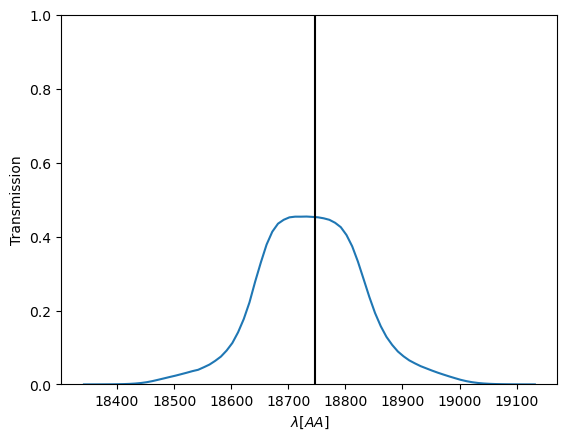

In [8]:
# Fetch one filter's transmission curve
tbl = SvoFps.get_transmission_data('JWST/NIRCam.F187N')
bp = SpectralElement(
    Empirical1D,
    points=tbl['Wavelength'].quantity.to(u.AA),
    lookup_table=tbl['Transmission'].data,
)

plt.figure()
plt.plot(tbl['Wavelength'], tbl['Transmission'])
plt.axvline(18746, c='black')
plt.ylim(0,1)
plt.ylabel('Transmission')
plt.xlabel(r'$\lambda [AA]$')

In [18]:
lam0 = 18746 *u.AA
T    = 100_000_000 * u.K
width = np.sqrt(8*np.log(2) * const.k_B* T / (const.m_p * const.c**2)).decompose()

print(lam0*width)

133.77913472785994 Angstrom


In [ ]:
vega = SourceSpectrum.from_vega()
sp_norm = sp.normalize(17 * units.VEGAMAG, bp, vegaspec=vega)

plt.plot(sp.waveset, sp(sp.waveset), 'b', label='original')
#plt.plot(sp_norm.waveset, sp_norm(sp_norm.waveset), 'r', label='Renormalized')

plt.xlim(18000, 20000)
plt.xlim(6000, 7000)
plt.legend(loc='best')

In [ ]:
obs= Observation(sp, bp)
print(obs.effstim(flux_unit=units.VEGAMAG) + 43* units.VEGAMAG)
